<style>
    /* This is only for styling the notebook for HTML export */
.jp-RenderedHTMLCommon {font: 11pt/1.45 "Times New Roman", Times, serif;}
.jp-Notebook { box-sizing: border-box; max-width: 960px; margin: 32px auto; padding: 0 24px; }
.jp-RenderedHTMLCommon p { text-align: justify; }
.jp-RenderedHTMLCommon h1 { font-size: 20pt; text-align: center; margin-bottom: .2em; }
.jp-RenderedHTMLCommon h2 { font-size: 12pt; text-align: center; font-variant: small-caps; }
.jp-RenderedHTMLCommon h3, .jp-RenderedHTMLCommon h4, .jp-RenderedHTMLCommon h5 { font-size: 11pt; font-style: italic; text-align: left; }
.jp-RenderedHTMLCommon .nb-author { text-align: center; margin: 0 0 1.25em; }
.jp-RenderedHTMLCommon .nb-tabcap { font-size: 9pt; text-align: center; font-variant: small-caps; }
.jp-RenderedHTMLCommon .nb-figcap { font-size: 9pt; text-align: left; }

/* Compact, centred layout for the exported HTML. */
body.jp-Notebook { width: 100%; max-width: 900px; margin: 24px auto; padding: 0 20px; }
body.jp-Notebook .jp-Cell { min-width: 0; }
body.jp-Notebook .jp-CodeMirrorEditor,
body.jp-Notebook .jp-CodeMirrorEditor pre,
body.jp-Notebook .jp-RenderedText pre { font: 9pt/1.35 Consolas, monospace !important; }
body.jp-Notebook .jp-RenderedText pre { white-space: pre-wrap; overflow-wrap: anywhere; }
body.jp-Notebook .jp-OutputArea img { max-width: 100%; height: auto; }
body.jp-Notebook .jp-Mermaid { display: flex; justify-content: center; }
body.jp-Notebook .jp-Mermaid svg { display: block; width: auto !important; height: auto !important; max-width: min(100%, 480px) !important; max-height: 650px; margin: 0 auto; }
body.jp-Notebook .nb-section > summary { cursor: pointer; margin: 1em 0 .4em; }
body.jp-Notebook .nb-section > summary h2,
body.jp-Notebook .nb-section > summary h3,
body.jp-Notebook .nb-section > summary h4 { display: inline; margin: 0; }
body.jp-Notebook .nb-code > summary { cursor: pointer; font: 9pt/1.35 Arial, sans-serif; color: #444; padding: 4px 8px; background: #f4f4f4; border: 1px solid #ddd; }
body.jp-Notebook .nb-code[open] > summary { margin-bottom: 4px; }
</style>
<script>
document.addEventListener("DOMContentLoaded", () => {
  const main = document.querySelector("body.jp-Notebook > main");
  if (!main) return;

  // Match the contents links to the numbered headings in the export.
  const links = new Map([...main.querySelectorAll('a[href^="#"]')].map(link =>
    [link.textContent.trim().match(/^\d+(?:\.\d+)*/)?.[0], link.hash.slice(1)]));
  for (const heading of main.querySelectorAll(".jp-RenderedMarkdown h2, .jp-RenderedMarkdown h3, .jp-RenderedMarkdown h4")) {
    const id = links.get(heading.textContent.trim().match(/^\d+(?:\.\d+)*/)?.[0]);
    if (id) { heading.id = id; heading.classList.add("nb-section-title"); }
  }

  // Native details keep sections open; code inputs start closed.
  const stack = [{level: 1, body: main}];
  for (const cell of [...main.children].filter(el => el.classList.contains("jp-Cell"))) {
    const content = cell.querySelector(".jp-RenderedMarkdown");
    const titles = [...(content?.children || [])].filter(el => el.classList.contains("nb-section-title"));
    if (!titles.length) { stack[stack.length - 1].body.append(cell); continue; }
    for (const heading of titles) {
      const level = Number(heading.tagName[1]);
      while (stack.length > 1 && stack[stack.length - 1].level >= level) stack.pop();
      const section = document.createElement("details");
      const summary = document.createElement("summary");
      const body = document.createElement("div");
      section.className = "nb-section";
      section.open = true;
      body.className = "nb-section-body";
      summary.append(heading);
      section.append(summary, body);
      stack[stack.length - 1].body.append(section);
      stack.push({level, body});
    }
    if (content.children.length) stack[stack.length - 1].body.append(cell); else cell.remove();
  }
  for (const cell of main.querySelectorAll(".jp-CodeCell")) {
    const input = cell.querySelector(":scope > .jp-Cell-inputWrapper");
    if (!input) continue;
    const details = document.createElement("details");
    const summary = document.createElement("summary");
    details.className = "nb-code";
    summary.textContent = "Code";
    input.before(details);
    details.append(summary, input);
  }
  function reveal(hash) {
    const target = hash && document.getElementById(decodeURIComponent(hash.slice(1)));
    for (let section = target?.closest("details.nb-section"); section; section = section.parentElement.closest("details.nb-section")) section.open = true;
  }
  document.addEventListener("click", event => {
    const link = event.target.closest('a[href^="#"]');
    if (link) reveal(link.hash);
  });
  window.addEventListener("hashchange", () => reveal(location.hash));
  reveal(location.hash);
});
</script>


# CSCU9YE Metaheuristics for Multi-Resource Workload Allocation



<p class="nb-author">Student ID: 30065980</p>



## Contents

- [1. Conceptual Understanding](#1-conceptual-understanding)
  - [1.1 What Decision Do We Have to Make?](#11-what-decision-do-we-have-to-make)
  - [1.2 Objective: Maximize Total Utility](#12-objective-maximize-total-utility)
  - [1.3 Constraints](#13-constraints)
- [2. Problem Formulation](#2-problem-formulation)
  - [2.1 Mathematical Model: Hardware-Constrained AI Model Selection](#21-mathematical-model-hardware-constrained-ai-model-selection)
    - [2.1.1 Sets, Indices, and Decision Variables](#211-sets-indices-and-decision-variables)
    - [2.1.2 Parameters](#212-parameters)
    - [2.1.3 Objective Function](#213-objective-function)
    - [2.1.4 Constraints](#214-constraints)
    - [2.1.5 Instance 1: 28 Models and 2 Resource Limits](#215-instance-1-28-models-and-2-resource-limits)
    - [2.1.6 Instance 2: 90 Models and 5 Resource Limits](#216-instance-2-90-models-and-5-resource-limits)
- [3. Computer Modelling](#3-computer-modelling)
  - [3.1 Data Loading and Global Helper](#31-data-loading-and-global-helper)
  - [3.2 Part 1: Baseline Discrete Hill-Climbing Local Search](#32-part-1-baseline-discrete-hill-climbing-local-search)
    - [3.2.1 Initialisation](#321-initialisation)
    - [3.2.2 Modification Procedure](#322-modification-procedure)
    - [3.2.3 Assessment and Selection](#323-assessment-and-selection)
    - [3.2.4 The Feasibility-Preserving Best-Improvement Hill Climbing Algorithm](#324-the-feasibility-preserving-best-improvement-hill-climbing-algorithm)
    - [3.2.5 Repeated Independent Runs](#325-repeated-independent-runs)
    - [3.2.6 Convergence Curves](#326-convergence-curves)
    - [3.2.7 Operator Contribution](#327-operator-contribution)
  - [3.3 Part 2: Advanced Population-Based Metaheuristic](#33-part-2-advanced-population-based-metaheuristic)
    - [3.3.1 Diversity-Preserving Steady-State Genetic Algorithm](#331-diversity-preserving-steady-state-genetic-algorithm)
    - [3.3.2 Initial Population](#332-initial-population)
    - [3.3.3 Fitness Evaluation](#333-fitness-evaluation)
    - [3.3.4 Parent Selection](#334-parent-selection)
    - [3.3.5 Variation: Uniform Crossover and Bit-Flip Mutation](#335-variation-uniform-crossover-and-bit-flip-mutation)
    - [3.3.6 Constraint Handling: Closed Greedy Drop-Add Repair](#336-constraint-handling-closed-greedy-drop-add-repair)
    - [3.3.7 Survival: Hamming-Distance Crowding and Elite Shielding](#337-survival-hamming-distance-crowding-and-elite-shielding)
    - [3.3.8 Complete DP-SSGA Algorithm](#338-complete-dp-ssga-algorithm)
    - [3.3.9 Search Behaviour and Population Diversity](#339-search-behaviour-and-population-diversity)
    - [3.3.10 Summary and Limitations](#3310-summary-and-limitations)
- [4. Part 3: Empirical Study and Hypothesis Testing](#4-part-3-empirical-study-and-hypothesis-testing)
  - [4.1 Research Question, Motivation and Hypotheses](#41-research-question-motivation-and-hypotheses)
    - [4.1.1 H1 — Anytime Solution Quality](#411-h1-anytime-solution-quality)
    - [4.1.2 H2 — Population Diversity](#412-h2-population-diversity)
    - [4.1.3 H3 — Execution Time](#413-h3-execution-time)
  - [4.2 Controlled Protocol and Algorithmic Variants](#42-controlled-protocol-and-algorithmic-variants)
  - [4.3 Engineering](#43-engineering)
    - [4.3.1 Shared Offspring Generation](#431-shared-offspring-generation)
    - [4.3.2 Generational Survival](#432-generational-survival)
    - [4.3.3 Weakest-First Steady-State Survival](#433-weakest-first-steady-state-survival)
    - [4.3.4 Complete Baseline Algorithm](#434-complete-baseline-algorithm)
    - [4.3.5 Performance Metrics](#435-performance-metrics)
    - [4.3.6 Run Validation](#436-run-validation)
  - [4.4 Experiment and Quantitative Findings](#44-experiment-and-quantitative-findings)
    - [4.4.1 One Experimental Run](#441-one-experimental-run)
    - [4.4.2 Matched-Seed Experiment](#442-matched-seed-experiment)
    - [4.4.3 Quantitative Summary](#443-quantitative-summary)
    - [4.4.4 Convergence and Diversity Curves](#444-convergence-and-diversity-curves)
    - [4.4.5 Hypothesis Testing](#445-hypothesis-testing)
- [5. References](#5-references)


## 1. Conceptual Understanding

I write this section only to serve as a descriptive understanding of the assignment before moving on to mathematical modeling and computer modeling.


### 1.1 What Decision Do We Have to Make?

- For each candidate model, we need to determine whether it should be **deployed** on the autonomous edge platform
- Determine which **combination of AI models** should be selected to operate together


### 1.2 Objective: Maximize Total Utility

- Functional utility: Maximize the combined utility provided by the selected AI models.
- Model selection: Prioritize combinations of models that provide higher overall utility.
- Resource efficiency: Achieve the highest possible utility without exceeding the available hardware resources.


### 1.3 Constraints

- Each model must either be selected or excluded
- The total resource consumption of selected models must not exceed the available capacity of each resource.
- The combined consumption of RAM, GPU compute, storage, power, and bandwidth, where applicable, must remain within their respective limit.
- All resource constraints must be satisfied simultaneously for a model selection to be feasible.
- A model combination is considered infeasible if it exceeds even one resource capacity.
- The resource requirements and utility values of each AI model are assumed to be fixed and known.


## 2. Problem Formulation

### 2.1 Mathematical Model: Hardware-Constrained AI Model Selection

The problem is a binary selection problem: each candidate AI model is either deployed or not deployed.

#### 2.1.1 Sets, Indices, and Decision Variables

Let $J$ be the set of candidate AI models and $I$ the set of resource types:

$$
J = \{1,2,\ldots,n\}, \qquad I = \{1,2,\ldots,m\}
$$

Here $j \in J$ identifies a model, $i \in I$ identifies a resource, $n$ is the number of candidate models, and $m$ is the number of resource types.

For every model $j$, define the binary decision variable:

$$
x_j =
\begin{cases}
1 & \text{if model } j \text{ is selected}, \\
0 & \text{otherwise}.
\end{cases}
$$

A complete candidate selection is the binary vector $x=(x_1,x_2,\ldots,x_n)$.

#### 2.1.2 Parameters

| Symbol | Definition |
|:---|:---|
| $p_j$ | Functional utility provided by model $j$ |
| $r_{i,j}$ | Consumption of resource $i$ by model $j$ |
| $b_i$ | Capacity available for resource $i$ |
| $n$ | Number of candidate models |
| $m$ | Number of resource constraints |

All values are fixed inputs from the corresponding dataset. The datasets do not label the physical resource units; consequently, this notebook refers to Resource 1, Resource 2, and so forth.

| Input | Instance 1 | Instance 2 |
|:---|---:|---:|
| Models ($n$) | 28 | 90 |
| Resources ($m$) | 2 | 5 |
| Capacity for Resource 1 | 500 | 2100 |
| Capacity for Resource 2 | 500 | 1100 |
| Capacity for Resource 3 | — | 3300 |
| Capacity for Resource 4 | — | 3700 |
| Capacity for Resource 5 | — | 3600 |

#### 2.1.3 Objective Function

Maximize the total utility of the selected models:

$$
\max f(x)=\sum_{j=1}^{n}p_j x_j
$$

If a model is selected ($x_j=1$), its utility is included; otherwise, it contributes zero.

#### 2.1.4 Constraints

For every resource $i$, the total consumption cannot exceed its capacity:

$$
\sum_{j=1}^{n}r_{i,j}x_j \le b_i, \qquad i=1,\ldots,m
$$

All decisions are binary:

$$
x_j \in \{0,1\}, \qquad j=1,\ldots,n
$$

A selection is **feasible** only if *every* resource limit is satisfied. This is the 0–1 multidimensional knapsack model provided in the assignment specification.

#### 2.1.5 Instance 1: 28 Models and 2 Resource Limits

Substituting the dataset dimensions and two capacities into the general model gives:

$$
\text{Maximize} \quad f(x)=\sum_{j=1}^{28}p_j x_j \tag{1}
$$

$$
\begin{aligned}
\text{Subject to} \quad & \sum_{j=1}^{28}r_{1,j}x_j \le b_1, \quad b_1=500 \\[5pt]
& \sum_{j=1}^{28}r_{2,j}x_j \le b_2, \quad b_2=500 \\[5pt]
& x_j \in \{0,1\}, \quad j=1,\ldots,28.
\end{aligned}\tag{2}
$$

Both resource constraints must hold for a feasible selection.

#### 2.1.6 Instance 2: 90 Models and 5 Resource Limits

The same model applies with five capacities:

$$
\text{Maximize} \quad f(x)=\sum_{j=1}^{90}p_j x_j \tag{3}
$$

$$
\begin{aligned}
\text{Subject to} \quad & \sum_{j=1}^{90}r_{1,j}x_j \le b_1, \quad b_1=2100 \\[5pt]
& \sum_{j=1}^{90}r_{2,j}x_j \le b_2, \quad b_2=1100 \\[5pt]
& \sum_{j=1}^{90}r_{3,j}x_j \le b_3, \quad b_3=3300 \\[5pt]
& \sum_{j=1}^{90}r_{4,j}x_j \le b_4, \quad b_4=3700 \\[5pt]
& \sum_{j=1}^{90}r_{5,j}x_j \le b_5, \quad b_5=3600 \\[5pt]
& x_j \in \{0,1\}, \quad j=1,\ldots,90.
\end{aligned}\tag{4}
$$

The mathematical model is unchanged between the two instances; only the input values and dimensions differ.

## 3. Computer Modelling

### 3.1 Data Loading and Global Helper

Before implementing a search algorithm, I load the two supplied workload instances. This gives the optimisation code access to the model utilities, resource demands, and capacity limits.

`%pip install scipy`

In [54]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
FEASIBILITY_TOL = 1e-9

I import `Path`, NumPy as `np`, and `matplotlib.pyplot` as `plt`, then set the global seed with `np.random.seed(42)`. `FEASIBILITY_TOL = 1e-9` handles floating-point rounding at the capacity boundary.

In [55]:
## Exact code provided by Sasikumar
def load_workload_instance(file_path):
    """
    Loads a hardware-constrained workload allocation dataset.
    
    Parameters:
        file_path (str): Path to the dataset plain text file (.txt).
        
    Returns:
        n (int): Number of candidate AI models.
        m (int): Number of hardware resource constraints.
        utilities (np.ndarray): 1D array of shape (n,) containing model utility scores (p_j).
        demands (np.ndarray): 2D array of shape (m, n) containing resource consumption demands (r_{i,j}).
        capacities (np.ndarray): 1D array of shape (m,) containing hardware capacity limits (b_i).
    """
    with open(file_path, 'r') as f:
        tokens = f.read().split()
        
    if not tokens:
        raise ValueError(f"Dataset file at '{file_path}' is empty or invalid.")
        
    n = int(tokens[0])
    m = int(tokens[1])
    idx = 2
    
    # Model utility scores (length n)
    utilities = np.array([float(x) for x in tokens[idx : idx + n]])
    idx += n
    
    # Resource demand matrix (shape m x n)
    demands = np.zeros((m, n))
    for i in range(m):
        demands[i, :] = [float(x) for x in tokens[idx : idx + n]]
        idx += n
        
    # Maximum hardware capacity limits (length m)
    capacities = np.array([float(x) for x in tokens[idx : idx + m]])
    
    return n, m, utilities, demands, capacities


Each dataset file stores the number of models, number of resources, utility scores, resource demands, and capacity limits in that order. `load_workload_instance()` reads this format and returns $n$, $m$, a utility vector, a demand matrix, and a capacity vector. I have kept the supplied function unchanged, as required. The demand matrix has one row per resource and one column per model, so its shape is $(m,n)$.

In [56]:
DATA_DIR = Path("Data")
instance1_path = DATA_DIR / "multi_resource_n28_m2.txt"
instance2_path = DATA_DIR / "multi_resource_n90_m5 (1).txt"

for file_path in (instance1_path, instance2_path):
    if not file_path.is_file():
        raise FileNotFoundError(f"Missing dataset file: {file_path}")

n1, m1, p1, R1, b1 = load_workload_instance(instance1_path)
n2, m2, p2, R2, b2 = load_workload_instance(instance2_path)

I load both datasets from the `Data/` folder with the supplied reader. The file checks catch missing datasets before optimisation begins. The returned $n$ and $m$ are the numbers of candidate models and resource types. Each $p_j$ is the utility of model $j$; the matrix `R` stores its resource demand $r_{i,j}$, and $b_i$ is the capacity available for resource $i$. Therefore, `p` has $n$ values, `R` has shape $(m,n)$, and `b` has $m$ values. The suffixes `1` and `2` identify the two instances.

In [57]:
print("Instance 1 loaded:", n1, "models and", m1, "resources")
print("Instance 2 loaded:", n2, "models and", m2, "resources")

Instance 1 loaded: 28 models and 2 resources
Instance 2 loaded: 90 models and 5 resources


In [58]:
# Instance 1
print("1. Utility scores shape (p_j)     :", p1.shape)
print("1. Resource demands shape (r_ij)  :", R1.shape)
print("1. Capacity limits (b_i)          :", b1)

1. Utility scores shape (p_j)     : (28,)
1. Resource demands shape (r_ij)  : (2, 28)
1. Capacity limits (b_i)          : [500. 500.]


In [59]:
# Instance 2
print("2. Utility scores shape (p_j)     :", p2.shape)
print("2. Resource demands shape (r_ij)  :", R2.shape)
print("2. Capacity limits (b_i)          :", b2)

2. Utility scores shape (p_j)     : (90,)
2. Resource demands shape (r_ij)  : (5, 90)
2. Capacity limits (b_i)          : [2100. 1100. 3300. 3700. 3600.]


The output shows that Instance 1 contains 28 models and 2 resources, while Instance 2 contains 90 models and 5 resources. Utility scores $p_j$ are stored in one-dimensional arrays. Resource demands $r_{i,j}$ are stored in matrices, with one row per resource and one column per model. Their shapes are $(2, 28)$ and $(5, 90)$.

The capacity vector $b_i$ gives the limit for each resource. Instance 1 has capacities of 500 for both resources. Instance 2 has capacities of 2100, 1100, 3300, 3700, and 3600. A feasible selection must stay within every capacity while maximizing the selected models' total utility.

Each model can be selected or excluded, so $n$ models give $2^n$ possible selections. Instance 1 has 28 models, giving:

$$
2^{28} = 268{,}435{,}456
$$

possible selections.

### 3.2 Part 1: Baseline Discrete Hill-Climbing Local Search

I structure `hill_climb()` around the three procedures described in [1, Sec. 2.1]: initialisation, modification, and assessment and selection. These procedures create a feasible start, explore alternative model combinations, and choose which improvement to accept. I generate neighbours with bit flips and one-for-one swaps, then use best-improvement selection to choose the next solution.

#### 3.2.1 Initialisation


In [60]:
def random_feasible_start(utilities, demands, capacities):
    """Build a feasible selection by checking models in random order."""
    selection = np.zeros(len(utilities), dtype=np.int8)
    resource_usage = np.zeros(len(capacities), dtype=float)

    for model in np.random.permutation(len(utilities)):
        proposed_usage = resource_usage + demands[:, model]
        if np.all(proposed_usage <= capacities + FEASIBILITY_TOL):
            selection[model] = 1
            resource_usage = proposed_usage

    return selection

I use `random_feasible_start()` to create a feasible starting selection. It begins with all models excluded, then considers them in a shuffled order and adds one only when both resource limits remain satisfied. A different order can use capacity differently and produce another feasible start. Repeating the search from these starts lets me assess sensitivity to initialisation. `FEASIBILITY_TOL` accounts for floating-point rounding only.

In [61]:
initial_solution = random_feasible_start(p1, R1, b1)
initial_utility = float(p1 @ initial_solution)
initial_resource_usage = R1 @ initial_solution

print("Initial selection:", initial_solution)
print("Initial utility:", initial_utility)
print("Resource use:", initial_resource_usage)
print("Feasible:", np.all(initial_resource_usage <= b1 + FEASIBILITY_TOL))

Initial selection: [1 1 0 0 1 0 0 0 1 1 1 1 1 1 0 1 1 1 1 0 0 1 1 1 1 1 1 0]
Initial utility: 66824.0
Resource use: [500. 492.]
Feasible: True


The output shows the initial selection, and array of 28 models. Each `1` marks a selected model, and each `0` marks an excluded model. The selected models have a total utility of 66,824 and use 500 units of Resource 1 and 492 units of Resource 2. These amounts are within the respective capacities of 500 units each, so the starting selection is feasible.

#### 3.2.2 Modification Procedure

In [62]:
def generate_feasible_neighbors(selection, demands, capacities):
    """Yield feasible one-bit flips and one-for-one swaps."""
    selected = np.flatnonzero(selection)
    unselected = np.flatnonzero(selection == 0)

    for model in range(len(selection)):
        candidate = selection.copy()
        candidate[model] = 1 - candidate[model]
        if np.all(demands @ candidate <= capacities + FEASIBILITY_TOL):
            yield candidate

    for remove_model in selected:
        for add_model in unselected:
            candidate = selection.copy()
            candidate[remove_model] = 0
            candidate[add_model] = 1
            if np.all(demands @ candidate <= capacities + FEASIBILITY_TOL):
                yield candidate


Bit flips are the simplest neighbourhood change for binary decisions: one model is added or removed. An addition may exceed a tight capacity, while removing a model alone reduces utility when model utilities are positive. However, Bit flips can leave the hill climber stuck when no single addition is feasible and every removal lowers utility. A one-for-one swap removes one selected model and adds one excluded model in the same candidate. The freed resources can make a replacement feasible without accepting an infeasible intermediate selection. The function copies each candidate and yields it only if every capacity is satisfied.

In [63]:
feasible_neighbors = list(generate_feasible_neighbors(initial_solution, R1, b1))
print("Feasible neighbouring selections:", len(feasible_neighbors))

Feasible neighbouring selections: 56


`generate_feasible_neighbors()` builds one-bit-flip and one-for-one-swap candidates, then keeps only those that satisfy both resource limits. For this starting selection, 56 is the number of feasible neighbours, our solution are only checked against the resource constraint, not utility yet. Filtering infeasible candidates keeps the hard constraints explicit, so the next procedure compares utility only among feasible choices.

#### 3.2.3 Assessment and Selection

In [64]:
def assess_and_select(current_solution, candidates, utilities):
    """Return the highest-utility strict improvement, if one exists."""
    current_utility = float(utilities @ current_solution)
    best_solution = current_solution.copy()
    best_utility = current_utility

    for candidate in candidates:
        candidate_utility = float(utilities @ candidate)
        if candidate_utility > best_utility:
            best_solution = candidate.copy()
            best_utility = candidate_utility

    return best_solution, best_utility, best_utility > current_utility

`assess_and_select()` calculates the current utility with the objective in (1), then scans every feasible neighbour and retains the highest-utility candidate. It accepts only a strict improvement, so equal utility does not trigger a move. This is best-improvement selection: it finishes checking the neighbourhood before choosing the next solution.

In [65]:
next_solution, next_utility, improved = assess_and_select(initial_solution, feasible_neighbors, p1)
assert next_utility >= initial_utility
print("Current utility:", initial_utility)
print("Selected utility:", next_utility)
print("Improvement found:", improved)

Current utility: 66824.0
Selected utility: 83476.0
Improvement found: True


For this seeded starting selection, the best of the 56 feasible neighbours raises utility from 66,824 to 83,476. The assertion `next_utility >= initial_utility` checks that utility has not fallen, and `improved` is `True` because a strictly better neighbour was found. This shows the assessment step selecting an improvement from one starting point.

#### 3.2.4 The Feasibility-Preserving Best-Improvement Hill Climbing Algorithm

In [66]:
def hill_climb(initial_solution, utilities, demands, capacities):
    solution = initial_solution.copy()
    utility = float(utilities @ solution)

    utility_history = [utility]
    solution_history = [solution.copy()]
    accepted_moves = 0

    while True:
        
        neighbours = generate_feasible_neighbors(solution, demands, capacities)
        candidate, candidate_utility, improved = assess_and_select(solution, neighbours, utilities)

        if not improved:
            break

        solution = candidate
        utility = candidate_utility
        accepted_moves += 1
        utility_history.append(utility)
        solution_history.append(solution.copy())

    return solution, utility, accepted_moves, utility_history, solution_history

At each iteration, `hill_climb()` checks the full feasible neighbourhood and accepts its highest-utility improvement. With 28 models, there are at most 28 bit flips and 196 swaps, so checking up to 224 candidates per iteration is manageable. First-improvement search would stop sooner, but its choice can depend on candidate order and may be a smaller gain. A local optimum in this neighbourhood may still fall short of the global optimum. Because capacities are hard limits, I reject infeasible neighbours before assessment; a penalty would require a chosen weight and could still rank infeasible solutions. The search stops when no feasible neighbour improves utility.

In [67]:
(
    final_solution,
    final_utility,
    accepted_moves,
    utility_history,
    solution_history,
) = hill_climb(initial_solution, p1, R1, b1)
print("Initial utility:", utility_history[0])
print("Final utility:", final_utility)
print("Accepted moves:", accepted_moves)
print("Final selection:", final_solution)
print("Resource consumption:", R1 @ final_solution)
print("Feasible:", np.all(R1 @ final_solution <= b1))

Initial utility: 66824.0
Final utility: 88927.0
Accepted moves: 4
Final selection: [0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 0 1 1 1 1 1 1 0]
Resource consumption: [490. 493.]
Feasible: True


The algorithm increased utility from 66,824 to 88,927 in this single run, an improvement of 22,103 (33.1%) over four accepted moves. The final selection uses 490 units of Resource 1 and 493 units of Resource 2, or 98% and 98.6% of capacity:

$$
\begin{aligned}
\text{Resource 1 utilisation} &= \frac{490}{500} \times 100 = 98\%, \\
\text{Resource 2 utilisation} &= \frac{493}{500} \times 100 = 98.6\%.
\end{aligned}
$$

The feasibility check returns `True`, confirming that the final selection satisfies both resource limits.

#### 3.2.5 Repeated Independent Runs

In [68]:
N_RUNS = 30
hill_climb_runs = []

for run in range(N_RUNS):
    initial = random_feasible_start(p1, R1, b1)

    solution, utility, moves, utility_history, solution_history = hill_climb(initial, p1, R1, b1)

    resource_usage = R1 @ solution
    assert np.all(resource_usage <= b1 + FEASIBILITY_TOL)

    hill_climb_runs.append({
        "run": run + 1,
        "initial_utility": utility_history[0],
        "final_utility": utility,
        "accepted_moves": moves,
        "resource_usage": resource_usage,
        "utility_history": utility_history,
        "solution_history": solution_history
    })

    print(f"Run {run + 1}: {utility_history[0]:.0f} → {utility:.0f}, {moves} moves")

Run 1: 99282 → 106380, 1 moves
Run 2: 45381 → 118009, 8 moves


Run 3: 70259 → 110440, 11 moves
Run 4: 93314 → 102292, 2 moves
Run 5: 92346 → 124430, 6 moves
Run 6: 81800 → 84552, 1 moves
Run 7: 73037 → 79767, 2 moves
Run 8: 110221 → 123669, 4 moves
Run 9: 59037 → 118750, 5 moves
Run 10: 74199 → 113286, 2 moves
Run 11: 99387 → 111662, 2 moves
Run 12: 97517 → 100472, 3 moves
Run 13: 84982 → 90460, 4 moves
Run 14: 88320 → 111917, 4 moves
Run 15: 109531 → 113316, 1 moves
Run 16: 91469 → 104464, 5 moves
Run 17: 77427 → 129183, 7 moves
Run 18: 80687 → 119960, 8 moves
Run 19: 67820 → 102737, 6 moves
Run 20: 74757 → 116301, 7 moves
Run 21: 110273 → 118596, 5 moves
Run 22: 73917 → 90125, 6 moves
Run 23: 69544 → 123910, 7 moves
Run 24: 53322 → 119750, 9 moves
Run 25: 78155 → 104628, 5 moves
Run 26: 61179 → 122062, 5 moves
Run 27: 88102 → 122564, 6 moves
Run 28: 75789 → 79767, 2 moves
Run 29: 102292 → 102292, 0 moves
Run 30: 102647 → 104037, 1 moves


I run the hill climber 30 times to see how starting selections affect final utility. `N_RUNS = 30` sets the run count. The global random stream is seeded once with `np.random.seed(42)` earlier in the notebook, so the sequence is reproducible when the notebook runs from the beginning. Each run creates a new feasible start, then applies hill climbing. An `assert` checks the final resource use, and `hill_climb_runs` stores utilities, accepted moves, resource use, and search histories for comparison and plotting.

In [69]:
initial_utilities = np.array([run["initial_utility"] for run in hill_climb_runs])
final_utilities = np.array([run["final_utility"] for run in hill_climb_runs])
moves = np.array([run["accepted_moves"] for run in hill_climb_runs])
resource_usage = np.array([run["resource_usage"] for run in hill_climb_runs])

print("Hill-Climbing Performance Summary")
print(f"Number of runs:       {N_RUNS}")

# Solution quality: measure the utility achieved and improvement from initialisation
print(f"Mean initial utility: {initial_utilities.mean():,.2f}")
print(f"Mean final utility:   {final_utilities.mean():,.2f}")
print(f"Mean improvement:     {(final_utilities - initial_utilities).mean():,.2f}")
print(f"Median final utility: {np.median(final_utilities):,.2f}")
print(f"Best final utility:   {final_utilities.max():,.0f}")
print(f"Worst final utility:  {final_utilities.min():,.0f}")

# Consistency: measure variation in final utility across different runs
print(f"Standard deviation:   {final_utilities.std(ddof=1):,.2f}")

# Search behaviour: measure accepted improvements and final resource utilisation
print(f"Mean accepted moves:  {moves.mean():.2f}")
print(f"Mean Resource 1 use:  {100 * np.mean(resource_usage[:, 0] / b1[0]):.2f}%")
print(f"Mean Resource 2 use:  {100 * np.mean(resource_usage[:, 1] / b1[1]):.2f}%")

Hill-Climbing Performance Summary
Number of runs:       30
Mean initial utility: 82,866.43
Mean final utility:   108,992.60
Mean improvement:     26,126.17
Median final utility: 111,789.50
Best final utility:   129,183
Worst final utility:  79,767
Standard deviation:   13,556.34
Mean accepted moves:  4.50
Mean Resource 1 use:  95.87%
Mean Resource 2 use:  99.12%


I use these metrics to assess **solution quality**, **consistency**, and **search behaviour**. Since the objective is to maximise total utility (1), initial and final utilities show improvement. The mean and median describe typical performance across 30 runs, while the best, worst, and standard deviation show variation between starting selections and the local optima they reach.

Mean accepted moves show how many improvements occur before the search stops. Resource utilisation shows how much of each capacity the final selections use; neither more moves nor higher resource use necessarily means a better solution. Across the runs, mean final utility was 108,992.60, with a best of 129,183 and a worst of 79,767. The standard deviation was 13,556.34. Run 3 reached 110,440 after 11 accepted moves; Run 6 reached 84,552 after one. These results show that starting selections can lead to different local optima. The metrics also provide a baseline for interpreting convergence curves and assessing future changes to the search method.

#### 3.2.6 Convergence Curves

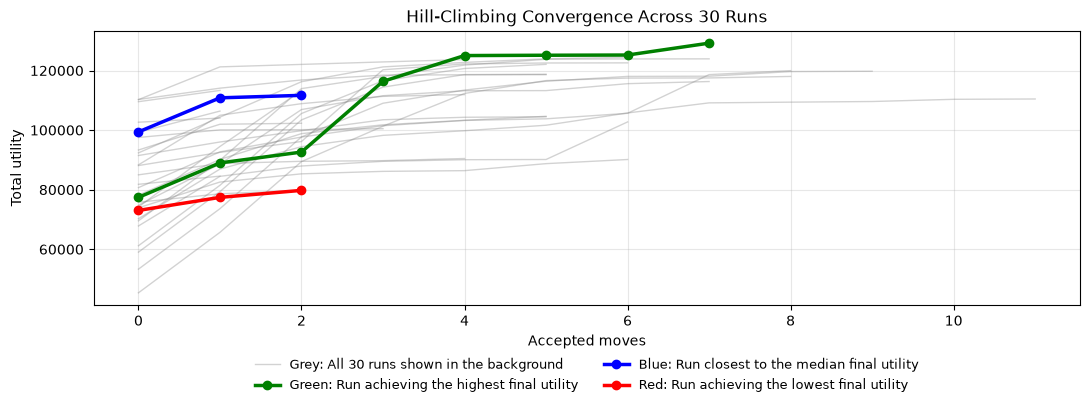

In [70]:
finals = np.array([run["final_utility"] for run in hill_climb_runs])
best = int(np.argmax(finals))
worst = int(np.argmin(finals))
median = int(np.argmin(np.abs(finals - np.median(finals))))

fig, ax = plt.subplots(figsize=(11, 5.5))

for run_index, run in enumerate(hill_climb_runs):
    history = run["utility_history"]
    label = "Grey: All 30 runs shown in the background" if run_index == 0 else "_nolegend_"
    ax.plot(range(len(history)), history, color="grey", alpha=0.35, linewidth=1, label=label)

highlights = [
    (best, "Green: Run achieving the highest final utility", "green"),
    (median, "Blue: Run closest to the median final utility", "blue"),
    (worst, "Red: Run achieving the lowest final utility", "red"),
]
for index, label, color in highlights:
    history = hill_climb_runs[index]["utility_history"]
    ax.plot(range(len(history)), history, marker="o", color=color, linewidth=2.5, label=label, zorder=3)

ax.set_xlabel("Accepted moves")
ax.set_ylabel("Total utility")
ax.set_title("Hill-Climbing Convergence Across 30 Runs")
ax.grid(alpha=0.3)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.20, 1, 1))
plt.show()

Across the 30 runs, utility generally rises as the hill climber accepts improvements, but final scores vary with the starting selection. The horizontal axis shows accepted moves and the vertical axis shows total utility. Grey lines show all runs; green, blue, and red highlight the highest, median-nearest, and lowest final utilities. Each run stops when its current feasible neighbourhood contains no improvement. The different final utilities show that the starting selection affects where the search stops.

#### 3.2.7 Operator Contribution

In [71]:
# Count which operator produced each accepted improvement
swap_moves = 0
bit_flips = 0

for run in hill_climb_runs:
    history = run["solution_history"]

    for before, after in zip(history[:-1], history[1:]):
        changed = np.count_nonzero(before != after)

        if changed == 2:       # One selected and one unselected model exchanged
            swap_moves += 1
        elif changed == 1:     # One model added or removed
            bit_flips += 1
        else:
            raise AssertionError("Unexpected move in the search history")

total_moves = swap_moves + bit_flips
assert total_moves == sum(run["accepted_moves"] for run in hill_climb_runs)

print(f"Accepted swaps:     {swap_moves} ({100 * swap_moves / total_moves:.2f}%)")
print(f"Accepted bit flips: {bit_flips} ({100 * bit_flips / total_moves:.2f}%)")
print(f"Total improvements: {total_moves}")


Accepted swaps:     123 (91.11%)
Accepted bit flips: 12 (8.89%)
Total improvements: 135


Across the 30 runs, the hill climber accepted 135 improvements: 123 swaps (91.11%) and 12 bit flips (8.89%). The shares are calculated as follows:

$$
\begin{aligned}
\text{Swap share} &= \frac{123}{135} \times 100 = 91.11\%, \\
\text{Bit-flip share} &= \frac{12}{135} \times 100 = 8.89\%.
\end{aligned}
$$

These percentages count accepted moves, not the utility gained by each operator, and swaps examine more candidates than bit flips. Most accepted improvements were swaps, which supports including replacements when capacity limits restrict additions.

### 3.3 Part 2: Advanced Population-Based Metaheuristic

Instance 2 has a much larger search space, with 90 binary model decisions and five resource constraints. The assignment gives the number of possible selections as follows:

$$
2^n = 2^{90} \approx 1.23 \times 10^{27}.
$$

That is about 1.23 octillion possible binary combinations. For this section, I use a variant of the genetic algorithm called a Diversity-Preserving Steady-State Genetic Algorithm (DP-SSGA). My goal is inclusion: I want separate niches to survive, not only to return the single best selection. SSGA is already exploitative itself [1], but, if one elite region takes over, the population may fill with very similar selections and lose alternatives. This makes the search not thorough. To counter this, I use Hamming-based crowding to help preserve alternatives and examine the recorded diversity to see how the population changes.

In practice, an engineer or manager may want to explore a diverse set of good configurations. I think it is better to keep promising alternatives in the search than to settle too quickly around a local optimum. To do this, I use a crowding layer based on Hamming distance, replacing the primitive SSGA replacement of the weakest offspring function. Each child competes with its closest match among all 49 non-elite configurations and replaces it only if its utility is higher.

#### 3.3.1 Diversity-Preserving Steady-State Genetic Algorithm

```mermaid
flowchart TD
    A["50 feasible 90-bit configurations"] --> A1["Evaluate initial population (50 fitness evaluations)"]
    A1 --> B["Binary tournament parent selection (t = 2)"]
    B --> C["Uniform crossover (0.8) and bit-flip mutation (1/90)"]
    C --> D["Closed greedy drop-add constraint repair"]
    D --> E["Evaluate repaired offspring utility"]
    E --> F["Hamming-distance crowding (protect global best)"]
    F --> G{"20,000 evaluations reached?"}
    G -- "No: create one offspring" --> B
    G -- "Yes" --> H["Return best feasible configuration"]
```


The operators are separate functions so their behaviour can be tested and their contribution compared under equal evaluation budgets.

#### 3.3.2 Initial Population

In [72]:
GA_POP_SIZE = 50
GA_EVALUATION_BUDGET = 20_000
GA_CROSSOVER_RATE = 0.8
GA_MUTATION_RATE = 1 / n2

I start the GA with `GA_POP_SIZE = 50` chromosomes so there are different model combinations to work with. A much smaller population could become similar after a few replacements, leaving crossover little variety to mix. A very large one would provide more starting choices, but scoring them would use more of the fixed `GA_EVALUATION_BUDGET = 20_000` and Hamming-distance crowding would have more chromosomes to compare for every child. I set `GA_CROSSOVER_RATE = 0.8` to mix parent decisions often and `GA_MUTATION_RATE = 1/90` so a 90-bit child has about one flipped decision on average. At a 50% mutation rate, around 45 decisions would flip per child, breaking many inherited combinations and increasing repair work. With mutation at 0%, crossover and repair would carry the search, giving it fewer ways to explore new combinations. SSGA replaces one chromosome at a time.

In [73]:
def initial_population(utilities, demands, capacities, size):
    n_models = len(utilities)
    population = np.zeros((size, n_models), dtype=np.int8)
    for i in range(size):
        usage = np.zeros(len(capacities), dtype=float)
        for j in np.random.permutation(n_models):
            if np.all(usage + demands[:, j] <= capacities):
                population[i, j] = 1
                usage += demands[:, j]
    return population

Each chromosome starts with all models excluded. I use `np.random.permutation()` to visit the models in a new random order and add one only when all five capacities remain satisfied. Different orders can produce different feasible starts, which lets me examine sensitivity to initialisation.

In [74]:
initial_ga_population = initial_population(p2, R2, b2, GA_POP_SIZE)
resource_usage = initial_ga_population @ R2.T
feasible_rows = np.all(resource_usage <= b2 + FEASIBILITY_TOL, axis=1)

assert initial_ga_population.shape == (GA_POP_SIZE, n2)
assert np.all((initial_ga_population == 0) | (initial_ga_population == 1))
assert feasible_rows.all()

print("Population shape:", initial_ga_population.shape)
print("Distinct configurations:", len(np.unique(initial_ga_population, axis=0)))
print("Feasible configurations:", feasible_rows.sum(), "/", GA_POP_SIZE)
print("First configuration demand:", resource_usage[0].astype(int))
print("Resource capacity limits:", b2.astype(int))

Population shape: (50, 90)
Distinct configurations: 50
Feasible configurations: 50 / 50
First configuration demand: [1328 1100 1910 1676 1571]
Resource capacity limits: [2100 1100 3300 3700 3600]


The output shows 50 distinct, feasible 90-bit configurations. `initial_ga_population @ R2.T` gives a 50-by-5 matrix of resource use, with one row per configuration and one column per resource. The assertions check the population shape, binary decisions and all five capacity limits.

#### 3.3.3 Fitness Evaluation

In [75]:
def fitness(solution, utilities):
    return float(utilities @ solution)

Following Luke (2013) [1], fitness assessment provides the basis for comparing candidate solutions during evolutionary search. I define `fitness()` once so the same utility objective (3) is used when scoring one individual and when evaluating the population.

In [76]:
# Vectorised fitness evaluation: one dot product per initial individual
initial_fitness = initial_ga_population @ p2
print("Mean initial fitness:", round(float(initial_fitness.mean()), 2))
print("Best initial fitness:", float(initial_fitness.max()))
print("Best initial model count:", int(initial_ga_population[np.argmax(initial_fitness)].sum()))

Mean initial fitness: 6018.02
Best initial fitness: 8160.0
Best initial model count: 48


`initial_ga_population @ p2` scores the 50 initial configurations in one operation. Their mean and best utilities show variation in starting quality. The GA stores these scores and updates one only when `hamming_crowding()` accepts a replacement, avoiding a full population reevaluation. Children are scored after repair.

#### 3.3.4 Parent Selection

In [77]:
def tournament_parent(population, scores):
    indices = np.random.randint(len(population), size=2)
    return population[indices[np.argmax(scores[indices])]].copy()

Next, I use binary tournament selection ($t=2$) to balance exploitation and exploration. `tournament_parent()` samples two population members, and the one with higher utility becomes a parent. This favours promising solutions while allowing weaker individuals to be selected occasionally, reducing selection pressure compared with larger tournaments. This stage also makes the algorithm because it compares only two fitness score at a time.

#### 3.3.5 Variation: Uniform Crossover and Bit-Flip Mutation

In [78]:
def uniform_crossover(parent_a, parent_b, probability=0.8):
    if np.random.random() >= probability:
        return parent_a.copy()
    mask = np.random.random(len(parent_a)) < 0.5
    return np.where(mask, parent_a, parent_b).astype(np.int8)

In [79]:
def bit_flip_mutation(child, probability):
    mutated = child.copy()
    mask = np.random.random(len(child)) < probability
    mutated[mask] = 1 - mutated[mask]
    return mutated

I use uniform crossover with probability 0.8 because model positions in the data file do not represent neighbouring physical components: taking genes from either parent independently avoids relying on a meaningful one-point cut. Bit-flip mutation changes each decision with probability $1/90$, giving an expected one flip per child, not exactly one. It introduces choices absent from one or both parents. Both operators may violate capacity limits; neither guarantees improvement.

**For example: sample of six AI model decisions**

**Step 1: Uniform crossover.** Suppose the crossover draw is $0.62 < 0.80$, so crossover takes place. A separate 50/50 choice at each position decides which parent supplies that model decision.

| Selection | Model 1 | Model 2 | Model 3 | Model 4 | Model 5 | Model 6 |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|
| Parent A | 1 | 1 | 0 | 0 | 1 | 0 |
| Parent B | 0 | 0 | 1 | 1 | 0 | 1 |
| Parent chosen | A | B | A | B | A | B |
| Child after crossover | **1** | **0** | **0** | **1** | **1** | **1** |

**Step 2: Bit-flip mutation.** Each of the 90 model decisions has a $1/90$ chance of flipping. In this example, Model 4 changes from `1` (deploy) to `0` (skip). The resulting child is `[1, 0, 0, 0, 1, 1]` for these six models:

| Selection | Model 1 | Model 2 | Model 3 | Model 4 | Model 5 | Model 6 |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|
| Before mutation | 1 | 0 | 0 | **1** | 1 | 1 |
| After mutation | 1 | 0 | 0 | **0** | 1 | 1 |

In [80]:
parent_a = tournament_parent(initial_ga_population, initial_fitness)
parent_b = tournament_parent(initial_ga_population, initial_fitness)
child = uniform_crossover(parent_a, parent_b, GA_CROSSOVER_RATE)
child = bit_flip_mutation(child, GA_MUTATION_RATE)
assert len(child) == n2
assert np.all((child == 0) | (child == 1))
print("After crossover and mutation: ", child)
print("Variation generated a valid 90-bit chromosome:", child.shape)

After crossover and mutation:  [1 0 0 0 1 0 1 0 0 1 0 0 1 0 1 0 0 1 0 0 0 0 1 1 1 1 1 0 0 0 1 1 0 1 0 0 1
 0 1 0 0 1 0 1 0 0 0 0 0 1 1 0 0 1 0 1 1 1 0 1 0 0 1 1 0 1 0 1 0 1 0 0 0 1
 0 0 1 0 1 1 1 0 0 0 1 0 0 0 0 1]
Variation generated a valid 90-bit chromosome: (90,)


This check confirms that selection, crossover and mutation produce a 90-bit binary chromosome in `child`, a feasible array of models. It does not test utility or feasibility; the repair step handles resource limits next.

#### 3.3.6 Constraint Handling: Closed Greedy Drop-Add Repair

In [81]:
def efficiency_order(utilities, demands, capacities):
    density = utilities / np.maximum((demands / capacities[:, None]).sum(axis=0), 1e-12)
    return np.argsort(density), np.argsort(-density)

I rank models by utility per total capacity-normalised demand, $e_j=p_j/\sum_{i=1}^{m}(r_{i,j}/b_i)$. Dividing each demand by its capacity makes resource use comparable across differently sized limits. This ranking supports greedy repair: removing low-efficiency models aims to release capacity with less utility loss, while adding high-efficiency models aims to recover utility efficiently, it is exploitative, limiting exploration. `efficiency_order()` calculates the ranking once before the search loop, avoiding repeated ranking work during repair.

In [82]:
def greedy_drop_add(solution, demands, capacities, drop_order, add_order):
    repaired = solution.copy()
    usage = demands @ repaired
    removed = added = 0
    for j in drop_order:
        if np.all(usage <= capacities + FEASIBILITY_TOL):
            break
        if repaired[j]:
            repaired[j] = 0
            usage -= demands[:, j]
            removed += 1
    for j in add_order:
        if not repaired[j] and np.all(usage + demands[:, j] <= capacities + FEASIBILITY_TOL):
            repaired[j] = 1
            usage += demands[:, j]
            added += 1
    return repaired, removed, added

Luke [1, Sec. 8.1] explains that crossover and mutation can produce offspring that violate hard resource constraints due to over-accumulation (selecting too many models) and overflow (total resource demand exceeding capacity). I therefore use `greedy_drop_add()` to make each child feasible before scoring it. The drop phase removes selected models from lowest to highest efficiency until all constrainst are met (4). The add phase then tries excluded models from highest to lowest efficiency and adds each one that fits; it also runs on already feasible offspring. A fixed ranking can remove a useful model, so this rule guarantees feasibility rather than the best possible utility. Repair ensures that only feasible configurations are evaluated, replacing penalty-weight tuning. The trade-off is that greedy introduce extra computation.

In [83]:
drop_order, add_order = efficiency_order(p2, R2, b2)

# Stress test: selecting every model breaches the hardware limits.
infeasible_test = np.ones(n2, dtype=np.int8)
repaired_test, removed, added = greedy_drop_add(infeasible_test, R2, b2, drop_order, add_order)
repaired_usage = R2 @ repaired_test
assert np.all(repaired_usage <= b2 + FEASIBILITY_TOL)

# Closure: no excluded model can now be added on its own.
for j in np.flatnonzero(repaired_test == 0):
    assert np.any(repaired_usage + R2[:, j] > b2 + FEASIBILITY_TOL)

print("Models removed:", removed, "| Models added:", added)
print("Repaired demand:", repaired_usage.astype(int))
print("Capacity limits:", b2.astype(int))
print("Feasible and single-add maximal: True")

Models removed: 48 | Models added: 1
Repaired demand: [1482 1099 1743 1601 2197]
Capacity limits: [2100 1100 3300 3700 3600]
Feasible and single-add maximal: True


I test `greedy_drop_add()` on `np.ones(n2, dtype=np.int8)`, which selects every model and exceeds the capacities. Repair removes 48 models and adds 1 model to the initial offspring pool (90 - 48 + 1 = 43 model selected); the assertions check feasibility and confirm that no excluded model can be added directly. In the full demonstration run, 9,753 of the 19,950 offspring (48.9%) were infeasible before repair, showing how often the operator is needed.

#### 3.3.7 Survival: Hamming-Distance Crowding and Elite Shielding

In [84]:
def hamming_crowding(population, scores, child, child_score, return_removed=False):
    # Reject duplicate chromosomes
    if np.any(np.all(population == child, axis=1)):
        if return_removed:
            return False, None
        return False
    
    # Protect the best individual
    elite_index = int(np.argmax(scores))
    eligible_indices = np.arange(len(population))
    eligible_indices = eligible_indices[eligible_indices != elite_index]

    # Find the most similar individual using Hamming distance
    distances = np.count_nonzero(population[eligible_indices] != child, axis=1)
    closest_indices = eligible_indices[distances == distances.min()]
    nearest = int(np.random.choice(closest_indices))

    # Reject offspring that do not improve their closest neighbour
    if child_score <= scores[nearest]:
        if return_removed:
            return False, None
        return False
    
    # Replace the neighbour with the better offspring
    removed = population[nearest].copy()
    population[nearest] = child
    scores[nearest] = child_score

    if return_removed:
        return True, removed
    return True

Mengshoel and Goldberg [2] describe crowding as competition between similar individuals. I use Hamming-distance crowding to encourage competition between structurally similar configurations rather than automatically replacing the weakest individual. Hamming distance is $H(x,y)=\sum_j|x_j-y_j|$. `hamming_crowding()` rejects exact duplicates and protects the highest-scoring chromosome.

By replacing the closest non-elite individual only when the offspring has higher utility, I aim to preserve alternative configurations while improving solution quality. Duplicate rejection avoids retaining identical chromosomes, while elite shielding protects the best solution found. This uses the similarity-based idea in [2] without a sampled window. From this point i expect that  more offspring will be included in competition due to crowding narrowing competition down to each neighbor.

In [85]:
def population_diversity(population):
    counts = population.sum(axis=0)
    n = len(population)
    return float(np.sum(counts * (n - counts)) / (n * (n - 1) / 2))

`population_diversity()` calculates mean pairwise Hamming distance from per-gene selection counts. For each gene, `counts * (n - counts)` gives the number of population pairs that differ there. Summing across genes and dividing by the number of pairs avoids explicit pairwise comparisons.

In [86]:
# Test elite shielding and duplicate rejection
# Utilities: 14 (elite), 10, and 3.
toy_population = np.array([[1, 1, 0, 0], [1, 0, 0, 0], [0, 0, 1, 0]], dtype=np.int8)
toy_utilities = np.array([10, 4, 3, 1])
toy_scores = toy_population @ toy_utilities
original_elite = toy_population[0].copy()

# The new child has utility 17 and is closest to the protected elite.
toy_child = np.array([1, 1, 1, 0], dtype=np.int8)
child_score = fitness(toy_child, toy_utilities)
accepted = hamming_crowding(toy_population, toy_scores, toy_child, child_score)

assert accepted
assert np.array_equal(toy_population[0], original_elite)

# A chromosome already in the population must be rejected.
duplicate_accepted = hamming_crowding(
    toy_population, toy_scores, original_elite, fitness(original_elite, toy_utilities)
)
assert not duplicate_accepted

print("Better child accepted:", accepted)
print("Original elite protected:", np.array_equal(toy_population[0], original_elite))
print("Duplicate rejected:", not duplicate_accepted)

Better child accepted: True
Original elite protected: True
Duplicate rejected: True


This is a focused test of two replacement rules rather than overall search quality. With a fixed population and child, `hamming_crowding()` accepts a better child without removing the protected best and rejects an identical copy.

#### 3.3.8 Complete DP-SSGA Algorithm

In [87]:
def run_dp_ssga(utilities, demands, capacities, population_size=50, evaluation_budget=20000,
                crossover_rate=0.8, mutation_rate=None, record_every=250, record_trajectory=False):
    if evaluation_budget < population_size or population_size < 2:
        raise ValueError("Evaluation budget must be at least the population size (>=2).")
    if mutation_rate is None:
        mutation_rate = 1 / len(utilities)

    # Before A: efficiency_order() (3.3.6) fixes the drop-add repair order.
    drop_order, add_order = efficiency_order(utilities, demands, capacities)
    # A (3.3.2): initial_population() builds feasible starting configurations.
    population = initial_population(utilities, demands, capacities, population_size)
    starting_population = population.copy()
    # A1: score the starts; population_size evaluations count toward the budget.
    scores = population @ utilities
    evaluations = population_size
    best_index = int(np.argmax(scores))
    best_solution = population[best_index].copy()
    best_score = float(scores[best_index])
    history_evals = [evaluations]
    history_best = [best_score]
    history_mean = [float(scores.mean())] if record_trajectory else None
    history_diversity = [population_diversity(population)]
    # Store full trajectories only when the plots need them.
    offspring_history = (
        np.empty((evaluation_budget - population_size, len(utilities)), dtype=np.int8)
        if record_trajectory else None
    )
    best_solution_path = [best_solution.copy()] if record_trajectory else None
    replacement_links = [] if record_trajectory else None
    replaced_count = repaired_count = drop_count = add_count = 0

    # G: repeat nodes B-F until the evaluation budget is reached.
    while evaluations < evaluation_budget:
        # B (3.3.4): tournament_parent() chooses parents from cached scores.
        parent_a = tournament_parent(population, scores)
        parent_b = tournament_parent(population, scores)
        # C (3.3.5): uniform_crossover() and bit_flip_mutation() create a child.
        child = uniform_crossover(parent_a, parent_b, crossover_rate)
        child = bit_flip_mutation(child, mutation_rate)
        if np.any(demands @ child > capacities + FEASIBILITY_TOL):
            repaired_count += 1
        # D (3.3.6): greedy_drop_add() repairs the child before scoring.
        child, removed, added = greedy_drop_add(child, demands, capacities, drop_order, add_order)
        drop_count += removed
        add_count += added
        # E (3.3.3): fitness() scores the repaired child.
        child_score = fitness(child, utilities)
        evaluations += 1
        # F (3.3.7): hamming_crowding() decides whether the child replaces a non-elite.
        if record_trajectory:
            offspring_history[evaluations - population_size - 1] = child
            replaced, removed_solution = hamming_crowding(population, scores, child, child_score, return_removed=True)
            if replaced:
                replacement_links.append((removed_solution, child.copy()))
        else:
            replaced = hamming_crowding(population, scores, child, child_score)
        if replaced:
            replaced_count += 1
        # After F: record a new best only when crowding admits the child.
        if child_score > best_score:
            assert replaced, "New global best must enter the population."
            best_score = child_score
            best_solution = child.copy()
            if record_trajectory:
                best_solution_path.append(best_solution.copy())
        # Sample population_diversity() (3.3.7) for the search plots.
        if evaluations % record_every == 0 or evaluations == evaluation_budget:
            history_evals.append(evaluations)
            history_best.append(best_score)
            if record_trajectory:
                history_mean.append(float(scores.mean()))
            history_diversity.append(population_diversity(population))

    # H: verify feasibility and return the best feasible configuration.
    assert np.all(demands @ population.T <= capacities[:, None] + FEASIBILITY_TOL)
    assert np.array_equal(population[np.argmax(scores)], best_solution)
    assert best_score == float(scores.max())
    return {
        "solution": best_solution,
        "utility": best_score,
        "population": population,
        "starting_population": starting_population,
        "scores": scores,
        "evaluations": evaluations,
        "replacements": replaced_count,
        "infeasible_offspring": repaired_count,
        "dropped_models": drop_count,
        "added_models": add_count,
        "evaluation_history": np.array(history_evals),
        "utility_history": np.array(history_best),
        "mean_population_utility_history": np.array(history_mean) if record_trajectory else None,
        "diversity_history": np.array(history_diversity),
        "offspring_history": offspring_history,
        "best_solution_path": np.array(best_solution_path) if record_trajectory else None,
        "replacement_links": replacement_links,
    }


`run_dp_ssga()` combines the separate initialisation, selection, variation, repair and replacement functions. It evaluates the initial population, then one offspring at a time until the budget is reached. For the demonstration run, I also record mean utility, offspring, global-best solutions and accepted replacements for the plots.

In [88]:
import time

start_time = time.perf_counter()
demo_ga_result = run_dp_ssga(
    p2, R2, b2,
    population_size=GA_POP_SIZE,
    evaluation_budget=GA_EVALUATION_BUDGET,
    crossover_rate=GA_CROSSOVER_RATE,
    mutation_rate=GA_MUTATION_RATE,
    record_trajectory=True
)
ga_runtime = time.perf_counter() - start_time

assert demo_ga_result["evaluations"] == GA_EVALUATION_BUDGET
assert np.all(R2 @ demo_ga_result["solution"] <= b2 + FEASIBILITY_TOL)
assert np.all((demo_ga_result["solution"] == 0) | (demo_ga_result["solution"] == 1))
assert np.all(np.diff(demo_ga_result["utility_history"]) >= 0)

print("Best feasible utility:", f'{demo_ga_result["utility"]:,.0f}')
print("Selected models:", int(demo_ga_result["solution"].sum()))
print("Resource use:", (R2 @ demo_ga_result["solution"]).astype(int))
print("Capacity limits:", b2.astype(int))
print("Fitness evaluations:", demo_ga_result["evaluations"])
print("Accepted replacements:", demo_ga_result["replacements"])
print("Offspring initially infeasible:", demo_ga_result["infeasible_offspring"])
print("Models dropped / added:", demo_ga_result["dropped_models"], "/", demo_ga_result["added_models"])
print("Runtime (seconds):", round(ga_runtime, 2))

Best feasible utility: 11,191
Selected models: 51
Resource use: [1777 1100 2259 2232 2418]
Capacity limits: [2100 1100 3300 3700 3600]
Fitness evaluations: 20000
Accepted replacements: 667
Offspring initially infeasible: 9753
Models dropped / added: 38275 / 30857
Runtime (seconds): 12.14


The demonstration run reaches utility 11,191 with 51 selected models after 20,000 evaluations. It accepts 667 replacements, and Resource 2 reaches its 1,100-unit limit. I use the next figures to examine how utility and diversity changed during that search.

#### 3.3.9 Search Behaviour and Population Diversity

I compare the best-so-far utility with the current population's mean utility and track mean pairwise Hamming distance for the single demonstration run.

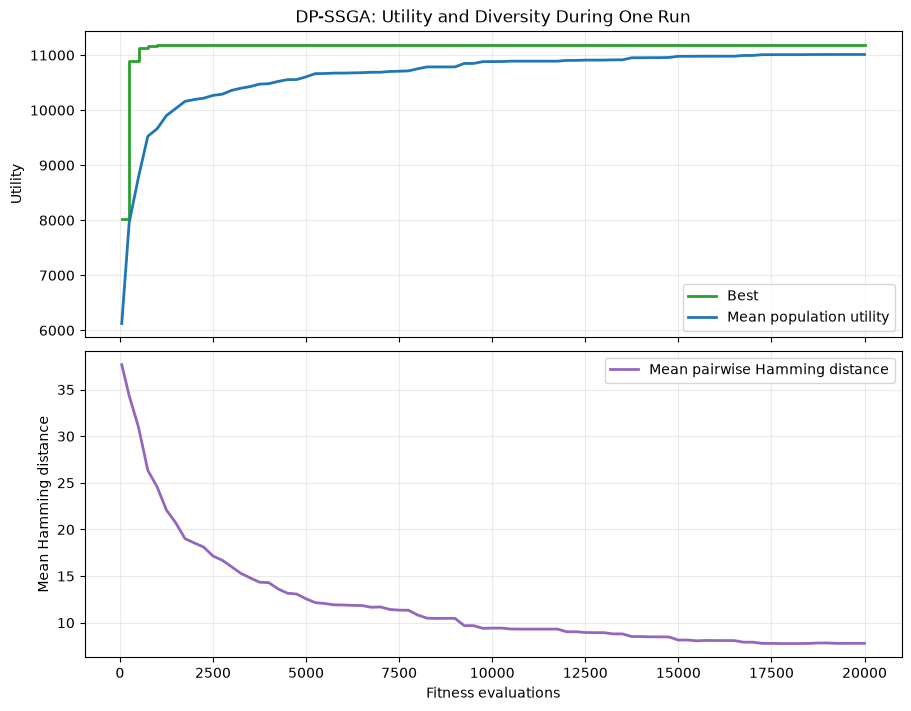

Initial population (50 evaluations):
  Best utility: 8,017
  Mean utility: 6,124
Final population (20,000 evaluations):
  Best utility: 11,191
  Mean utility: 11,012


In [89]:
evals = demo_ga_result["evaluation_history"]
best_history = demo_ga_result["utility_history"]
mean_history = demo_ga_result["mean_population_utility_history"]
diversity_history = demo_ga_result["diversity_history"]

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True, constrained_layout=True)

axes[0].step(evals, best_history, where="post", color="tab:green", linewidth=2, label="Best")
axes[0].plot(evals, mean_history, color="tab:blue", linewidth=2, label="Mean population utility")
axes[0].set_ylabel("Utility")
axes[0].set_title("DP-SSGA: Utility and Diversity During One Run")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(evals, diversity_history, color="tab:purple", linewidth=2, label="Mean pairwise Hamming distance")
axes[1].set_ylabel("Mean Hamming distance")
axes[1].set_xlabel("Fitness evaluations")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.show()
print(f"Initial population ({evals[0]:,} evaluations):")
print(f"  Best utility: {best_history[0]:,.0f}")
print(f"  Mean utility: {mean_history[0]:,.0f}")
print(f"Final population ({evals[-1]:,} evaluations):")
print(f"  Best utility: {best_history[-1]:,.0f}")
print(f"  Mean utility: {mean_history[-1]:,.0f}")


By the 1,500-evaluation checkpoint, the best recorded utility had risen from 8,017 to 11,191. The population mean rose more gradually, from about 6,124 to 11,012 by the end of the run, narrowing the gap between the two lines. This fits the steady-state design: one offspring is evaluated at a time, while elite shielding keeps the best selection in the population until a better one is found.

Mean pairwise Hamming distance fell from 37.68 to 7.79 over the same run. The population gained utility as its model selections became more alike.

I project the initial population and feasible offspring into two PCA axes to see where new configurations appear during the search. Points are coloured by utility, grey lines show accepted replacements, and the red path follows successive global-best configurations. The axis labels report how much of the 90-bit variation this view retains.

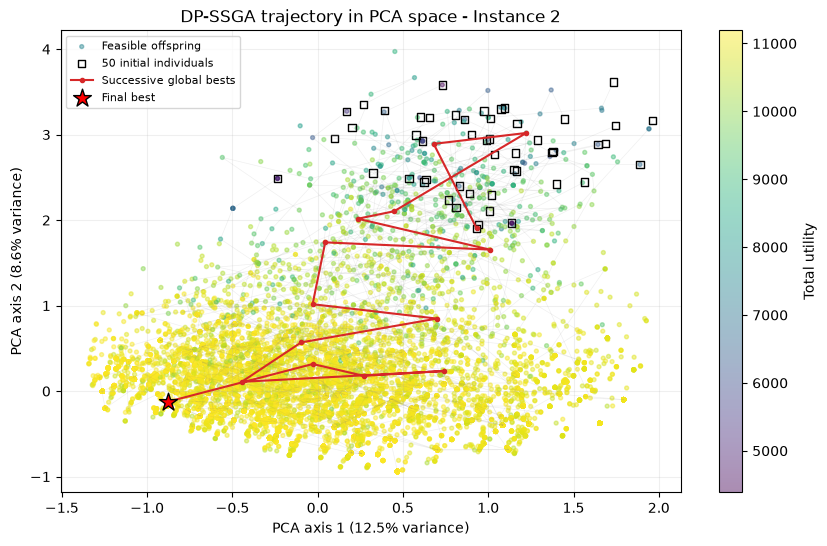

PCA variance explained: axis 1 12.49%, axis 2 8.60%, combined 21.08%


In [90]:
initial = demo_ga_result["starting_population"]
offspring = demo_ga_result["offspring_history"]
configurations = np.vstack((initial, offspring))
centre = configurations.mean(axis=0)
_, singular_values, directions = np.linalg.svd(configurations - centre, full_matrices=False)
components = directions[:2]
axis_variance_pct = 100 * singular_values[:2] ** 2 / np.sum(singular_values ** 2)
coordinates = (configurations - centre) @ components.T
best_path = (demo_ga_result["best_solution_path"] - centre) @ components.T
replacement_links = np.asarray(demo_ga_result["replacement_links"], dtype=np.int8)

fig, ax = plt.subplots(figsize=(10, 6))
for old, new in replacement_links:
    link_xy = (np.array([old, new]) - centre) @ components.T
    ax.plot(link_xy[:, 0], link_xy[:, 1], color="grey", alpha=0.12, linewidth=0.5)
points = ax.scatter(coordinates[len(initial):, 0], coordinates[len(initial):, 1],
                    c=offspring @ p2, cmap="viridis", s=8, alpha=0.45,
                    label="Feasible offspring")
ax.scatter(coordinates[:len(initial), 0], coordinates[:len(initial), 1],
           marker="s", facecolors="none", edgecolors="black", s=28,
           label=f"{len(initial)} initial individuals")
ax.plot(
    best_path[:, 0], best_path[:, 1], color="tab:red", marker="o",
    markersize=3, linewidth=1.5, label="Successive global bests"
)
ax.scatter(
    best_path[-1, 0], best_path[-1, 1], marker="*", color="red",
    edgecolors="black", s=180, label="Final best", zorder=4
)
fig.colorbar(points, ax=ax, label="Total utility")
ax.set_title("DP-SSGA trajectory in PCA space - Instance 2")
ax.set_xlabel(f"PCA axis 1 ({axis_variance_pct[0]:.1f}% variance)")
ax.set_ylabel(f"PCA axis 2 ({axis_variance_pct[1]:.1f}% variance)")
ax.legend(loc="best", fontsize=8)
ax.grid(alpha=0.2)
plt.show()
print(
    f"PCA variance explained: axis 1 {axis_variance_pct[0]:.2f}%, "
    f"axis 2 {axis_variance_pct[1]:.2f}%, combined {axis_variance_pct.sum():.2f}%"
)

The two PCA axes capture 21.08% of the variation in the plotted configurations. The 50 starting selections sit mainly above the denser cloud of later offspring, while the red path follows successive best-found selections to the final result. This plot includes offspring generated during the search, so I use the Hamming curve above to judge how the retained population's diversity changed.

#### 3.3.10 Summary and Limitations

In the demonstration run, DP-SSGA returned a feasible configuration with utility 11,191 after 20,000 fitness evaluations. The plots show that utility rose early while population diversity fell during the run.

On the bad side, The fixed greedy repair ranking may favour similar resource-efficient configurations, potentially restricting exploration. Hamming crowding also requires additional similarity comparisons, but its benefit over conventional fitness-based replacement, and diversity preserving effectiveness, has not yet been established within this experiment. Furthermore, only one population size and set of variation probabilities were tested. These limitations motivate a controlled comparison of others variant such as generational GA, SSGA and DP-SSGA under equal fitness-evaluation budgets for the part 3.

## 4. Part 3: Empirical Study and Hypothesis Testing

### 4.1 Research Question, Motivation and Hypotheses

Following the findings and limitations of our DP-SSGA, I raise the following research question:

**Research question:** How does population replacement affect solution quality, diversity, and computational cost for Instance 2 (90 models and five constraints)?

To answer this question, I compare two additional variants with our existing DP-SSGA: the Generational Genetic Algorithm (baseline GA) and standard Steady-State Genetic Algorithm (SSGA). All three share the same initialisation, binary tournament selection, uniform crossover, bit-flip mutation, and greedy drop-add repair.

Based on the differences in their replacement mechanisms, I formulate three hypotheses:

#### 4.1.1 H1 — Anytime Solution Quality

I expect fitness-based SSGA to reach high utility earlier because accepted offspring immediately displace weak solutions and influence subsequent parent selection, whereas generational replacement makes less immediate use of successful offspring.

- **H₀:** No systematic difference in anytime solution quality among the three GAs.
- **H₁:** At least one GA differs systematically in anytime solution quality.

#### 4.1.2 H2 — Population Diversity

I expect DP-SSGA to retain more structural diversity because it restricts competition to similar configurations. This assumption is consistent with the initial design choice.

- **H₀:** DP-SSGA does not maintain greater diversity than SSGA.
- **H₁:** DP-SSGA maintains greater diversity than SSGA.

#### 4.1.3 H3 — Execution Time

I expect DP-SSGA to take longer because Hamming-distance crowding took 121 seconds on a batch of 30 run. This requires additional comparisons. Hardware check is out of this study scope.

- **H₀:** DP-SSGA is not slower than SSGA.
- **H₁:** DP-SSGA is slower than SSGA.

### 4.2 Controlled Protocol and Algorithmic Variants

| Setting | Generational GA | SSGA | DP-SSGA |
|---|---|---|---|
| Initial Population size | 50 | 50 | 50 |
| Population model | Generational | Steady-state | Steady-state with Hamming crowding |
| Parent choice | Binary tournament ($t=2$) | Same | Same |
| Variation | Uniform crossover (0.8), bit flips ($1/90$) | Same | Same |
| Repair | Greedy drop-add | Same | Same |
| Survival | Batch selection: Previous elite + best 49 offspring | Select for Death: Replace weakest non-elite if improved | Hamming Crowding: Replace nearest non-elite if improved |
| Budget | 20,000 fitness evaluations | Same | Same |
| Trials | 30 matched seeds | Same | Same |

I keep the population size, 20,000-evaluation budget, variation operators, and repair method the same across all three variants. This narrows the scope down and gives me a direct comparison of **weakest-first and Hamming-crowding survival** in the two steady-state GAs. I interpret the generational GA separately because it also changes when parents are updated.

In [91]:
from scipy.stats import friedmanchisquare, wilcoxon
import itertools
import time
import pandas as pd

PART4_SEEDS = range(200, 230)
PART4_VARIANTS = ("Generational GA", "SSGA", "DP-SSGA")
PART4_RECORD_EVERY = 250
PART4_CHECKPOINTS = np.r_[GA_POP_SIZE,np.arange(PART4_RECORD_EVERY, GA_EVALUATION_BUDGET + 1, PART4_RECORD_EVERY)]
PART4_REFERENCE_UTILITY = float(demo_ga_result["utility"])

print(f"Part 2 best observed utility (comparison reference): {PART4_REFERENCE_UTILITY:,.0f}")

Part 2 best observed utility (comparison reference): 11,191


These global variables establish a consistent framework for comparing the three GA variants. `PART4_SEEDS` defines 30 reproducible runs, while `PART4_VARIANTS` identifies the algorithms being compared. `PART4_CHECKPOINTS` tracks convergence at fixed evaluation intervals, and `PART4_REFERENCE_UTILITY` provides the best observed utility from Part 2 as a performance benchmark.

### 4.3 Engineering

#### 4.3.1 Shared Offspring Generation

In [92]:
def part4_create_offspring(population, scores, utilities, demands, capacities,
                           drop_order, add_order, crossover_rate, mutation_rate):
    """Select parents, apply variation, repair, and evaluate one child."""
    parent_a = tournament_parent(population, scores)
    parent_b = tournament_parent(population, scores)

    child = uniform_crossover(parent_a, parent_b, crossover_rate)
    child = bit_flip_mutation(child, mutation_rate)
    child, _, _ = greedy_drop_add(child, demands, capacities, drop_order, add_order)

    child_score = fitness(child, utilities)
    return child, child_score

`part4_create_offspring()` reuses the selection, crossover, mutation, and greedy repair operators from Section 3.3. Keeping offspring generation separate ensures that the two new baselines use the same operators; DP-SSGA continues to use the existing `run_dp_ssga()` implementation, while the baseline and SSGA will be using this function

#### 4.3.2 Generational Survival

In [93]:
def part4_generational_survival(population, scores, children, child_scores):
    """Keep the old elite and the best offspring for the next generation."""
    population_size = len(population)

    elite_index = int(np.argmax(scores))
    elite_solution = population[elite_index].copy()
    elite_score = float(scores[elite_index])

    offspring_order = np.argsort(-child_scores, kind="stable")
    survivor_indices = offspring_order[:population_size - 1]

    next_population = np.vstack((elite_solution[None, :], children[survivor_indices]))
    next_scores = np.r_[elite_score, child_scores[survivor_indices]]
    return next_population, next_scores

Because in the Generational GA, parents remain fixed while a complete batch of offspring is produced. I declare a new function for the survival selection. For the baseline GA, it first checks whether child already exists in population and rejects duplicates. Next, elite_index identifies the individual with the highest fitness in scores, protecting it from replacement. The remaining individuals are stored in eligible_indices, where weakest_index identifies the lowest-scoring candidate. The offspring is accepted only when child_score exceeds scores[weakest_index], updating both population and scores; otherwise, the function returns False.

#### 4.3.3 Weakest-First Steady-State Survival

In [94]:
def part4_weakest_survival(population, scores, child, child_score):
    """Replace the weakest non-elite member only when the child improves it."""
    # Apply the same duplicate rejection and elite protection as DP-SSGA.
    if np.any(np.all(population == child, axis=1)):
        return False

    elite_index = int(np.argmax(scores))
    eligible_indices = np.arange(len(population))
    eligible_indices = eligible_indices[eligible_indices != elite_index]

    weakest_index = int(eligible_indices[np.argmin(scores[eligible_indices])])
    if child_score <= scores[weakest_index]:
        return False

    population[weakest_index] = child
    scores[weakest_index] = child_score
    return True

Same is applied to generic SSGA, `part4_weakest_survival()` changes one population member at a time. However, it is more exploitative because it rejects the worst member at a time. First, it checks whether child already exists in population and rejects duplicates to avoid storing identical solutions. Next, elite_index identifies the individual with the highest fitness in scores, while eligible_indices excludes this elite from replacement. The weakest_index then identifies the lowest-scoring eligible individual. If child_score is greater than scores[weakest_index], the function updates both population and scores and returns True; otherwise, it returns False.

#### 4.3.4 Complete Baseline Algorithm

In [95]:
def run_part4_baseline(
    utilities, demands, capacities, variant, population_size=50,
    evaluation_budget=20000, crossover_rate=0.8,
    mutation_rate=None, record_every=250,
):
    """Run the Generational GA or SSGA with a fixed evaluation budget."""
    if variant not in ("Generational GA", "SSGA"):
        raise ValueError("This runner supports Generational GA and SSGA only")
    if population_size < 2 or evaluation_budget < population_size:
        raise ValueError("Invalid population size or evaluation budget")
    if variant == "Generational GA" and (evaluation_budget - population_size) % population_size:
        raise ValueError("Generational GA needs complete offspring batches")
    if record_every <= 0:
        raise ValueError("Checkpoint spacing must be positive")
    if mutation_rate is None:
        mutation_rate = 1 / len(utilities)

    # Initialise and score a common-sized feasible population.
    drop_order, add_order = efficiency_order(utilities, demands, capacities)
    population = initial_population(utilities, demands, capacities, population_size)
    scores = population @ utilities
    evaluations = population_size

    best_index = int(np.argmax(scores))
    best_solution = population[best_index].copy()
    best_score = float(scores[best_index])

    evaluation_history = [evaluations]
    utility_history = [best_score]
    diversity_history = [population_diversity(population)]

    while evaluations < evaluation_budget:
        if variant == "Generational GA":
            # Produce the entire generation from unchanged parents.
            children = np.empty_like(population)
            child_scores = np.empty(population_size, dtype=float)
            for index in range(population_size):
                children[index], child_scores[index] = part4_create_offspring(
                    population, scores, utilities, demands, capacities,
                    drop_order, add_order, crossover_rate, mutation_rate
                )

            population, scores = part4_generational_survival(population, scores, children, child_scores)
            evaluations += population_size
        else:
            # SSGA immediately considers one offspring for replacement.
            child, child_score = part4_create_offspring(
                population, scores, utilities, demands, capacities,
                drop_order, add_order, crossover_rate, mutation_rate
            )
            part4_weakest_survival(population, scores, child, child_score)
            evaluations += 1

        current_best_index = int(np.argmax(scores))
        if scores[current_best_index] > best_score:
            best_score = float(scores[current_best_index])
            best_solution = population[current_best_index].copy()

        if evaluations % record_every == 0 or evaluations == evaluation_budget:
            evaluation_history.append(evaluations)
            utility_history.append(best_score)
            diversity_history.append(population_diversity(population))

    assert evaluations == evaluation_budget
    assert np.all(demands @ population.T <= capacities[:, None] + FEASIBILITY_TOL)
    assert np.all(demands @ best_solution <= capacities + FEASIBILITY_TOL)
    assert best_score == float(scores.max())

    return {
        "solution": best_solution,
        "utility": best_score,
        "evaluations": evaluations,
        "evaluation_history": np.asarray(evaluation_history),
        "utility_history": np.asarray(utility_history),
        "diversity_history": np.asarray(diversity_history),
    }

Within the main while loop, two conditional branches distinguish the variant being evaluated. Generational GA produces a batch of offspring and updates the population through generational survival, whereas SSGA generates and evaluates one offspring at a time using weakest-first replacement. Both baselines record the best-so-far utility and population diversity at identical evaluation checkpoints, ensuring a consistent comparison of convergence behaviour.

#### 4.3.5 Performance Metrics

In [96]:
def part4_time_average(values, evaluation_points):
    """Compute an evaluation-weighted average using the trapezoidal rule."""
    interval_lengths = np.diff(evaluation_points)
    interval_means = (values[:-1] + values[1:]) / 2
    area = np.sum(interval_lengths * interval_means)
    total_interval = evaluation_points[-1] - evaluation_points[0]
    return float(area / total_interval)

Then, part4_time_average() function supports Hypothesis 1 (H1) by measuring how efficiently each algorithm discovers high-quality solutions throughout the search, rather than considering only the final utility. interval_lengths calculates the evaluations between checkpoints, while interval_means estimates the average best-so-far utility within each interval. Using the trapezoidal rule, area sums these weighted values and divides them by total_interval to obtain the overall anytime utility. This allows us to compare convergence performance under the same evaluation budget. A higher anytime utility indicates that an algorithm finds better solutions earlier, and provides quantitative evidences. 

#### 4.3.6 Run Validation

In [97]:
def part4_validate_result(result):
    """Check budget, checkpoint alignment, feasibility, and utility history."""
    solution = result["solution"]

    assert result["evaluations"] == GA_EVALUATION_BUDGET
    assert np.array_equal(result["evaluation_history"], PART4_CHECKPOINTS)
    assert np.all((solution == 0) | (solution == 1))
    assert np.all(R2 @ solution <= b2 + FEASIBILITY_TOL)
    assert np.all(np.diff(result["utility_history"]) >= 0)
    assert result["utility"] == float(p2 @ solution)

This function checks that each run follows the same evaluation budget and checkpoints, produces a feasible binary solution, and records non-decreasing best-so-far utility. This ensures our experimental results are consistent and valid before statistical comparison.

### 4.4 Experiment and Quantitative Findings

#### 4.4.2 Matched-Seed Experiment

In [ ]:
def part4_run_experiments():
    """Run all three GA variants across 30 matched seeds."""
    runs = {variant: [] for variant in PART4_VARIANTS}

    settings = {
        "population_size": GA_POP_SIZE,
        "evaluation_budget": GA_EVALUATION_BUDGET,
        "crossover_rate": GA_CROSSOVER_RATE,
        "mutation_rate": GA_MUTATION_RATE,
        "record_every": PART4_RECORD_EVERY,
    }

    for i, seed in enumerate(PART4_SEEDS):
        # Rotate execution order to reduce timing bias.
        shift = i % len(PART4_VARIANTS)
        order = PART4_VARIANTS[shift:] + PART4_VARIANTS[:shift]

        for variant in order:
            np.random.seed(seed)
            start_time = time.perf_counter()

            if variant == "DP-SSGA":
                result = run_dp_ssga(p2, R2, b2,**settings,record_trajectory=False)
            else:
                result = run_part4_baseline(p2, R2, b2, variant,**settings)

            runtime = time.perf_counter() - start_time
            part4_validate_result(result)

            history = result["evaluation_history"]

            runs[variant].append({
                "seed": seed,
                "final_utility": float(result["utility"]),
                "anytime_utility": part4_time_average(result["utility_history"], history),
                "mean_diversity": part4_time_average(result["diversity_history"], history),
                "runtime_s": runtime,
                "utility_curve": result["utility_history"],
                "diversity_curve": result["diversity_history"],
            })

        if (i + 1) % 5 == 0:
            print(f"Completed {i + 1}/{len(PART4_SEEDS)} seeds")

    return runs


part4_runs = part4_run_experiments()
print("Finished:", len(PART4_SEEDS), "runs for each of", len(PART4_VARIANTS), "variants")


Here we conduct our conducts our 30-seed experiment to compare Generational GA, SSGA, and DP-SSGA. First, runs stores the results for each algorithm, while settings ensures they use the same population size, evaluation budget, crossover rate, mutation rate, and recording intervals. For each seed in PART4_SEEDS, we rotate the execution order to reduce potential timing bias and use np.random.seed(seed) for reproducibility. The function then calls either run_dp_ssga() or run_part4_baseline() depending on the variant. We measure runtime, validate each result using part4_validate_result(), and record final utility, anytime utility (H1), mean diversity (H2), and runtime (H3), alongside their convergence histories.

#### 4.4.3 Quantitative Summary

In [ ]:
def part4_make_records(runs):
    """Convert the experimental results into a table with one row per run."""
    rows = []
    for variant in PART4_VARIANTS:
        for run in runs[variant]:
            rows.append({
                "variant": variant,
                "seed": run["seed"],
                "final_utility": run["final_utility"],
                "anytime_utility": run["anytime_utility"],
                "mean_diversity": run["mean_diversity"],
                "runtime_s": run["runtime_s"],
            })
    return pd.DataFrame(rows)

In [ ]:
def part4_summarise_records(records):
    """Calculate final quality, anytime quality, diversity, and runtime summaries."""
    summary = records.groupby("variant", sort=False).agg(
        runs=("seed", "count"),
        final_mean=("final_utility", "mean"),
        final_std=("final_utility", "std"),
        final_best=("final_utility", "max"),
        anytime_mean=("anytime_utility", "mean"),
        diversity_mean=("mean_diversity", "mean"),
        runtime_mean_s=("runtime_s", "mean"),
        runtime_std_s=("runtime_s", "std"),
    )

    reaches_reference = records["final_utility"] >= PART4_REFERENCE_UTILITY
    reference_hits = (
        records.assign(reaches_reference=reaches_reference)
        .groupby("variant", sort=False)["reaches_reference"]
        .sum()
    )
    summary["reference_hits"] = reference_hits.astype(int)
    return summary

In [ ]:
part4_records = part4_make_records(part4_runs)
part4_summary = part4_summarise_records(part4_records)

print("Quantitative comparison — 30 runs per variant (20,000 evaluations per run)")
print("The Part 2 reference is the best observed utility, not a proven optimum.")
print(part4_summary.round(2).to_string())

Quantitative comparison — 30 runs per variant (20,000 evaluations per run)
The Part 2 reference is the best observed utility, not a proven optimum.
                 runs  final_mean  final_std  final_best  anytime_mean  diversity_mean  runtime_mean_s  runtime_std_s  reference_hits
variant                                                                                                                              
Generational GA    30    11189.27       2.02     11191.0      11169.11            1.90            4.18           1.27              17
SSGA               30    11191.00       0.00     11191.0      11173.85            5.17            4.16           1.11              30
DP-SSGA            30    11191.00       0.00     11191.0      11170.87           11.43            4.81           1.51              30


#### 4.4.4 Convergence and Diversity Curves


In [ ]:
def part4_curve_statistics(runs, variant, curve_name):
    """Return the mean and standard deviation at each recorded checkpoint."""
    curves = np.stack([run[curve_name] for run in runs[variant]])
    return curves.mean(axis=0), curves.std(axis=0)

In [ ]:
def part4_plot_progress(runs):
    """Plot anytime utility and population diversity for all GA variants."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

    for variant in PART4_VARIANTS:
        utility_mean, utility_std = part4_curve_statistics(runs, variant, "utility_curve")
        diversity_mean, diversity_std = part4_curve_statistics(runs, variant, "diversity_curve")

        axes[0].plot(PART4_CHECKPOINTS, utility_mean, label=variant)
        axes[0].fill_between(
            PART4_CHECKPOINTS, utility_mean - utility_std,
            utility_mean + utility_std, alpha=0.12
        )
        axes[1].plot(PART4_CHECKPOINTS, diversity_mean, label=variant)
        axes[1].fill_between(
            PART4_CHECKPOINTS, diversity_mean - diversity_std,
            diversity_mean + diversity_std, alpha=0.12
        )

    axes[0].set(title="Anytime best feasible utility", xlabel="Fitness evaluations", ylabel="Utility")
    axes[1].set(
        title="Population diversity", xlabel="Fitness evaluations",
        ylabel="Mean pairwise Hamming distance (bits)"
    )
    for axis in axes:
        axis.grid(alpha=0.2)
        axis.legend()
    plt.show()

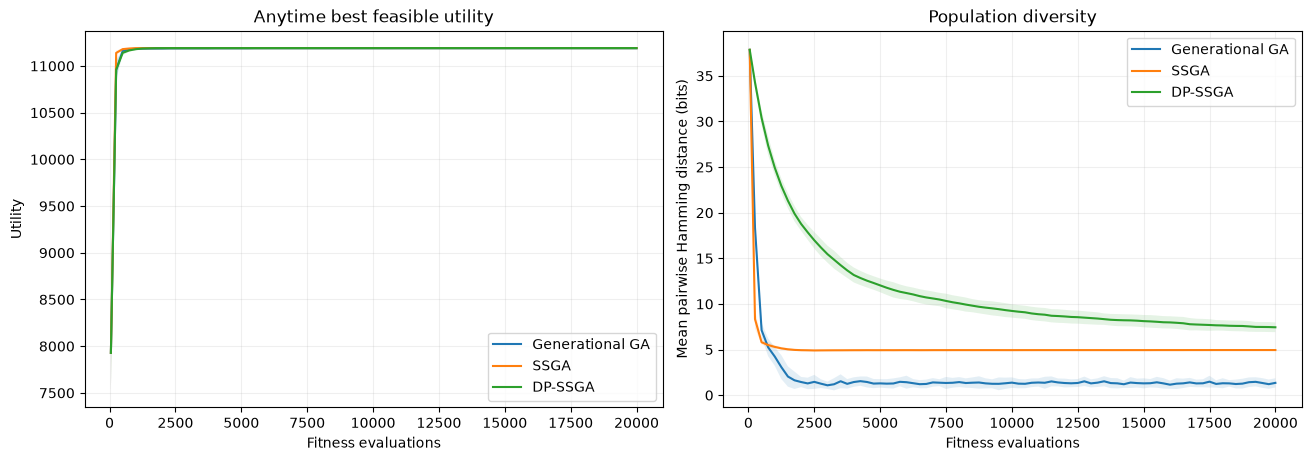

In [ ]:
part4_plot_progress(part4_runs)

Similary to the plot used for DP-SSGA, we apply the same utility and Hamming diversity preservation figure to the experiment. Shading represents variation between seeds, not confidence intervals.

4.3.5 Friedman and Wilcoxon Tests

In [ ]:
def part4_metric_values(runs, variant, metric):
    """Read a metric in seed order for one variant."""
    return np.array([run[metric] for run in runs[variant]], dtype=float)



In [ ]:
def part4_paired_wilcoxon(first, second):
    """Two-sided paired Wilcoxon p-value (1.0 for identical samples)."""
    if np.allclose(first, second, atol=1e-10, rtol=0):
        return 1.0
    return float(wilcoxon(first, second).pvalue)

In [ ]:
def part4_compare_three(runs, metric):
    """Friedman test and all three paired Wilcoxon comparisons."""
    values = {
        variant: part4_metric_values(runs, variant, metric)
        for variant in PART4_VARIANTS
    }
    samples = list(values.values())
    identical = all(np.allclose(samples[0], sample, atol=1e-10, rtol=0)
                    for sample in samples[1:])
    friedman_p = 1.0 if identical else float(friedmanchisquare(*samples).pvalue)

    pairwise_p = {
        (first, second): part4_paired_wilcoxon(values[first], values[second])
        for first, second in itertools.combinations(PART4_VARIANTS, 2)
    }
    return {"friedman_p": friedman_p, "wilcoxon_p": pairwise_p}

In [ ]:
def part4_pair_p(tests, metric, first, second):
    """Read the p-value of a pair regardless of its displayed order."""
    pairs = tests[metric]["wilcoxon_p"]
    return pairs.get((first, second), pairs.get((second, first)))

In [ ]:
part4_tests = {
    metric: part4_compare_three(part4_runs, metric)
    for metric in ("anytime_utility", "mean_diversity", "runtime_s")
}
print(f"H1 — Anytime utility, Friedman p = {part4_tests['anytime_utility']['friedman_p']:.4g}")

H1 — Anytime utility, Friedman p = 9.925e-11


In [ ]:
diversity_test = part4_tests["mean_diversity"]
print(f"H2 — Diversity, Friedman p = {diversity_test['friedman_p']:.4g}")
print("DP-SSGA vs SSGA, Wilcoxon p = "
      f"{part4_pair_p(part4_tests, 'mean_diversity', 'DP-SSGA', 'SSGA'):.4g}")

H2 — Diversity, Friedman p = 9.358e-14
DP-SSGA vs SSGA, Wilcoxon p = 1.863e-09


In [ ]:
runtime_test = part4_tests["runtime_s"]
print(f"H3 — Runtime, Friedman p = {runtime_test['friedman_p']:.4g}")
print("DP-SSGA vs SSGA, Wilcoxon p = "
      f"{part4_pair_p(part4_tests, 'runtime_s', 'DP-SSGA', 'SSGA'):.4g}")

H3 — Runtime, Friedman p = 0.004369
DP-SSGA vs SSGA, Wilcoxon p = 0.01454


In [ ]:
def part4_statistical_table(tests):
    """Summarise Friedman and three Wilcoxon comparisons per metric."""
    rows = []
    labels = {
        "anytime_utility": "Anytime utility",
        "mean_diversity": "Population diversity",
        "runtime_s": "Runtime (seconds)",
    }
    for metric, label in labels.items():
        result = tests[metric]
        row = {"Metric": label, "Friedman p": result["friedman_p"]}
        for first, second in itertools.combinations(PART4_VARIANTS, 2):
            row[f"{first} vs {second}"] = result["wilcoxon_p"][(first, second)]
        rows.append(row)
    return pd.DataFrame(rows).set_index("Metric")

In [ ]:
part4_statistical_results = part4_statistical_table(part4_tests)
print("Friedman (three variants) and paired Wilcoxon (every pair); unadjusted p-values")
print(part4_statistical_results.to_string(float_format=lambda value: f"{value:.4g}"))

Friedman (three variants) and paired Wilcoxon (every pair); unadjusted p-values
                      Friedman p  Generational GA vs SSGA  Generational GA vs DP-SSGA  SSGA vs DP-SSGA
Metric                                                                                                
Anytime utility        9.925e-11                1.863e-09                     0.01546        1.863e-09
Population diversity   9.358e-14                1.863e-09                   1.863e-09        1.863e-09
Runtime (seconds)       0.004369                    0.612                    0.007111          0.01454


In [ ]:
def part4_paired_effect(runs, first, second, metric, bootstrap_samples=5000):
    """Summarise matched-seed differences with a reproducible bootstrap CI."""
    first_values = part4_metric_values(runs, first, metric)
    second_values = part4_metric_values(runs, second, metric)
    differences = first_values - second_values

    rng = np.random.default_rng(2026)
    resampled_means = rng.choice(differences, size=(bootstrap_samples, len(differences)), replace=True).mean(axis=1)
    lower, upper = np.quantile(resampled_means, [0.025, 0.975])

    return {"mean": float(differences.mean()),"lower": float(lower),"upper": float(upper),"wins": int(np.sum(differences > 0)),}


part4_effects = {
    "SSGA − Generational GA (anytime utility)": part4_paired_effect(part4_runs, "SSGA", "Generational GA", "anytime_utility"),
    "DP-SSGA − SSGA (anytime utility)": part4_paired_effect(part4_runs, "DP-SSGA", "SSGA", "anytime_utility"),
    "DP-SSGA − SSGA (diversity, bits)": part4_paired_effect(part4_runs, "DP-SSGA", "SSGA", "mean_diversity"),
    "DP-SSGA − SSGA (runtime, seconds)": part4_paired_effect(part4_runs, "DP-SSGA", "SSGA", "runtime_s"),
}

part4_effect_table = pd.DataFrame.from_dict(part4_effects, orient="index")
part4_effect_table["wins"] = part4_effect_table["wins"].astype(str) + f"/{len(PART4_SEEDS)}"
print("Paired effects: first variant minus second variant")
print(part4_effect_table.round(2).to_string())

Paired effects: first variant minus second variant
                                          mean  lower  upper   wins
SSGA − Generational GA (anytime utility)  4.74   3.70   5.96  30/30
DP-SSGA − SSGA (anytime utility)         -2.98  -3.40  -2.57   0/30
DP-SSGA − SSGA (diversity, bits)          6.26   6.08   6.45  30/30
DP-SSGA − SSGA (runtime, seconds)         0.65   0.15   1.21  22/30


## 5. References

[1] S. Luke, *Essentials of Metaheuristics*, 2nd ed. Lulu, 2013. [Online]. Available: https://people.cs.gmu.edu/~sean/book/metaheuristics/

[2] O. J. Mengshoel and D. E. Goldberg, “The Crowding Approach to Niching in Genetic Algorithms,” Evolutionary Computation, vol. 16, no. 3, pp. 315–354, 2008. doi: https://doi.org/10.1162/evco.2008.16.3.315

[3] GeeksforGeeks, “Friedman Test,” Jul. 23, 2025. [Online]. Available: https://www.geeksforgeeks.org/dsa/friedman-test/. [Accessed: Nov. 25, 2026].

[4] GeeksforGeeks, “Wilcoxon Signed Rank Test,” Jul. 27, 2025. [Online]. Available: https://www.geeksforgeeks.org/machine-learning/wilcoxon-signed-rank-test/. [Accessed: Nov. 25, 2026].